# 2026 Microbial species frequencies and community phenotype
# Autoencoder machine-learning

## Prerequisites

In [1]:
cwd = "/scratch/project_2000746/anthosun/2026FQPH/"

### Software

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

ModuleNotFoundError: No module named 'torch'

In [3]:
# train/test mask with 1/4 for testing
from numpy.random import default_rng
rng = default_rng()

def draw_train_test_masks(X):
    
    whole = np.arange(X.shape[0])
    whole = whole.reshape((len(whole) // 8, 8,))
    
    mask = []
    for i in range(len(whole)):
        for j in rng.choice(8, size = 2, replace=False):
            mask.append(whole[i,j])
    mask = np.array(mask)
    
    whole = whole.flatten()
    test_mask = np.array([x in mask for x in whole])
    train_mask = np.array([not x in mask for x in whole])
    
    return train_mask, test_mask

In [19]:
class FeedForwardAutoencoder(nn.Module):
    """
    Basic feed forward network with relu activations
    """
    def __init__(self, input_size, output_size, bottleneck_size):
        super().__init__()

        # ----- Encoder -----
        self.encoder = nn.Sequential(
            nn.Linear(input_size, 100),
            nn.ReLU(),
            nn.Linear(100, 50),
            nn.ReLU(),
            nn.Linear(50, 50),
            nn.ReLU(),
            nn.Linear(50, bottleneck_size),
            nn.ReLU()
        )

        # ----- Decoder -----
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_size, 50),
            nn.ReLU(),
            nn.Linear(50, 50),
            nn.ReLU(),
            nn.Linear(50, 100),
            nn.ReLU(),
            nn.Linear(100, output_size)   # No activation (outputs real positive values)
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        return out


def train_autoencoder(
    model,
    df_input: pd.DataFrame,
    df_output: pd.DataFrame,
    bottleneck_size: int,
    epochs: int = 100,
    learning_rate: float = 0.0001
):
    """
    function to fit autoencoder to trainig data
    """
    # Convert DataFrame → torch tensor
    X = torch.tensor(df_input.values, dtype=torch.float32)
    Y = torch.tensor(df_output.values, dtype=torch.float32)

    #model = FeedForwardAutoencoder(input_size, bottleneck_size, output_size)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()
    #criterion = nn.L1Loss()

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()

        output = model(X)
        loss = criterion(output, Y)

        loss.backward()
        optimizer.step()

#        if epoch % 200 == 0 or epoch == 1:
#            print(f"Epoch {epoch}/{epochs} | Loss: {loss.item():.6f}")

    return model

### Data preprocessing

In [20]:
FR = pd.read_csv("FR.csv", index_col = [0,1,2,3], header = [0,1])
F = FR.xs("freq", level = "strs", axis = 1)
R = FR.drop("freq", level = "strs", axis = 1).drop("Rclid", level = "feat", axis = 1)

In [21]:
train_mask, test_mask = draw_train_test_masks(FR)

In [22]:
# INPUT AND OUTPUT TABLES AS PANDAS DATAFRAMES
input_df = F.iloc[train_mask]
output_df = R.iloc[train_mask]

In [23]:
#MODEL PARAMETERS
LATENT_K = 5 # bottleneck layer size for latent representation
N_EPOCHS = 5000
LEARNING_RATE = 1e-3

In [24]:
model = train_autoencoder(
    model = FeedForwardAutoencoder(input_size= input_df.shape[1], output_size=output_df.shape[1], bottleneck_size=LATENT_K),
    df_input=input_df,
    df_output=output_df,
    bottleneck_size=LATENT_K,
    epochs=N_EPOCHS,
    learning_rate=LEARNING_RATE
)

In [25]:
def fit_model(input_df,
              output_df,
              bottleneck_size = LATENT_K,
              epochs = N_EPOCHS,
              learning_rate = LEARNING_RATE,
             ):
    
    model = train_autoencoder(model = FeedForwardAutoencoder(input_size= input_df.shape[1],
                                                             output_size=output_df.shape[1],
                                                             bottleneck_size=LATENT_K
                                                            ),
                              df_input=input_df,
                              df_output=output_df,
                              bottleneck_size=LATENT_K,
                              epochs=N_EPOCHS,
                              learning_rate=LEARNING_RATE,
                             )
    return model

In [26]:
def R2(model, X, Y):
    
    Yhat = model(torch.tensor(X, dtype=torch.float32)).detach().numpy()
    RSS = (Y - Yhat)**2
    
    Yavg = Y.mean(axis = 0)
    TSS = (Y - Yavg)**2
    
    return 1 - RSS.sum() / TSS.sum()    

In [27]:
R2(model, F.iloc[test_mask].values, R.iloc[test_mask].values)

0.31802100997672345

# Predictions

## From frequencies to phenotypes

### All

In [27]:
nreps = 10

strss = R.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):
    
    train_mask, test_mask = draw_train_test_masks(FR)
    
    # predict all stressors together
    
    model = fit_model(F.iloc[train_mask], R.iloc[train_mask],)
    trn = R2(model, F.iloc[train_mask].values, R.iloc[train_mask].values)
    tst = R2(model, F.iloc[test_mask].values, R.iloc[test_mask].values)
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        model = fit_model(F.iloc[train_mask], R.xs(strs, level="strs", axis=1).iloc[train_mask],)
        trn = R2(model, F.iloc[train_mask].values, R.xs(strs, level="strs", axis=1).iloc[train_mask].values)
        tst = R2(model, F.iloc[test_mask].values, R.xs(strs, level="strs", axis=1).iloc[test_mask].values)
        res[:,s+1,r] = [trn, tst]

In [28]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("autoencoder_F2R.csv", sep = ",", )

### From frequencies to phenotypes in ANC

In [28]:
FR = pd.read_csv("FR.csv", index_col = [0,1,2,3], header = [0,1])
F = FR.xs("freq", level = "strs", axis = 1)
R = FR.drop("freq", level = "strs", axis = 1).drop("Rclid", level = "feat", axis = 1)

F = F.xs("ANC", level = "hist", axis = 0)
R = R.xs("ANC", level = "hist", axis = 0)

In [30]:
nreps = 10

strss = R.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):
    
    train_mask, test_mask = draw_train_test_masks(F)
    
    # predict all stressors together
    
    model = fit_model(F.iloc[train_mask], R.iloc[train_mask],)
    trn = R2(model, F.iloc[train_mask].values, R.iloc[train_mask].values)
    tst = R2(model, F.iloc[test_mask].values, R.iloc[test_mask].values)
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        model = fit_model(F.iloc[train_mask], R.xs(strs, level="strs", axis=1).iloc[train_mask],)
        trn = R2(model, F.iloc[train_mask].values, R.xs(strs, level="strs", axis=1).iloc[train_mask].values)
        tst = R2(model, F.iloc[test_mask].values, R.xs(strs, level="strs", axis=1).iloc[test_mask].values)
        res[:,s+1,r] = [trn, tst]

In [31]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("autoencoder_F2R_ANC.csv", sep = ",", )

### From frequencies to phenotypes in EVO

In [32]:
FR = pd.read_csv("FR.csv", index_col = [0,1,2,3], header = [0,1])
F = FR.xs("freq", level = "strs", axis = 1)
R = FR.drop("freq", level = "strs", axis = 1).drop("Rclid", level = "feat", axis = 1)

F = F.xs("EVO", level = "hist", axis = 0)
R = R.xs("EVO", level = "hist", axis = 0)

In [33]:
nreps = 10

strss = R.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):
    
    train_mask, test_mask = draw_train_test_masks(F)
    
    # predict all stressors together
    
    model = fit_model(F.iloc[train_mask], R.iloc[train_mask],)
    trn = R2(model, F.iloc[train_mask].values, R.iloc[train_mask].values)
    tst = R2(model, F.iloc[test_mask].values, R.iloc[test_mask].values)
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        model = fit_model(F.iloc[train_mask], R.xs(strs, level="strs", axis=1).iloc[train_mask],)
        trn = R2(model, F.iloc[train_mask].values, R.xs(strs, level="strs", axis=1).iloc[train_mask].values)
        tst = R2(model, F.iloc[test_mask].values, R.xs(strs, level="strs", axis=1).iloc[test_mask].values)
        res[:,s+1,r] = [trn, tst]

In [34]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("autoencoder_F2R_EVO.csv", sep = ",", )

## From phenotypes to frequencies

In [37]:
nreps = 10

strns = F.columns.get_level_values("feat").unique()
nstrn = len(strns)

res = np.zeros((2, nstrn + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):
    
    train_mask, test_mask = draw_train_test_masks(FR)
    
    # predict all stressors together
    
    model = fit_model(R.iloc[train_mask], F.iloc[train_mask],)
    trn = R2(model, R.iloc[train_mask].values, F.iloc[train_mask].values)
    tst = R2(model, R.iloc[test_mask].values, F.iloc[test_mask].values)
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strn in enumerate(strns):
        model = fit_model(R.iloc[train_mask], pd.DataFrame(F.loc[train_mask,strn]),)
        trn = R2(model, R.iloc[train_mask].values, pd.DataFrame(F.loc[train_mask,strn]).values)
        tst = R2(model, R.iloc[test_mask].values, pd.DataFrame(F.loc[test_mask,strn]).values)
        res[:,s+1,r] = [trn, tst]

C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppDa

C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppData\Local\Temp\ipykernel_1084\780591868.py:9: RuntimeWarning: divide by zero encountered in double_scalars
  return 1 - RSS.sum() / TSS.sum()
C:\Users\Anthony\AppDa

In [40]:
R2F = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strns), index = ["trn_avg", "trn_mdn"], ).T
R2F = pd.concat([R2F, pd.DataFrame(res[1], index = ["all"] + list(strns), )], axis = 1)
R2F.to_csv("autoencoder_R2F.csv", sep=",", )

# Plotting Fig. S4

In [16]:
# ordering of strains based on the variance of their frequencies
F_index = ["all"] + pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,]).var(axis=0).sort_values(ascending=False).index.to_list()

# ordering of stressors based on the variance of the per-capita growth rates that they induce
R_index = ["all"] + pd.read_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], ).unstack().groupby("strs").var().sort_values(ascending=False).index.to_list()

In [23]:
F2R = pd.read_csv("{}/data/autoencoder_F2R.csv".format(cwd), index_col=[0]).loc[R_index]
R2F = pd.read_csv("{}/data/autoencoder_R2F.csv".format(cwd), index_col=[0]).loc[F_index]
F2R_ANC = pd.read_csv("{}/data/autoencoder_F2R_ANC.csv".format(cwd), index_col=[0])#.loc[F_index]
F2R_EVO = pd.read_csv("{}/data/autoencoder_F2R_EVO.csv".format(cwd), index_col=[0])#.loc[F_index]

F2R_all = pd.concat({"ANC+EVO": F2R, "ANC": F2R_ANC, "EVO": F2R_EVO, }, names = ["hist", "strs"])

F2R_all.rename({"all": "all stressors"}, inplace = True)
R2F.rename({"all": "all sp."}, inplace = True)

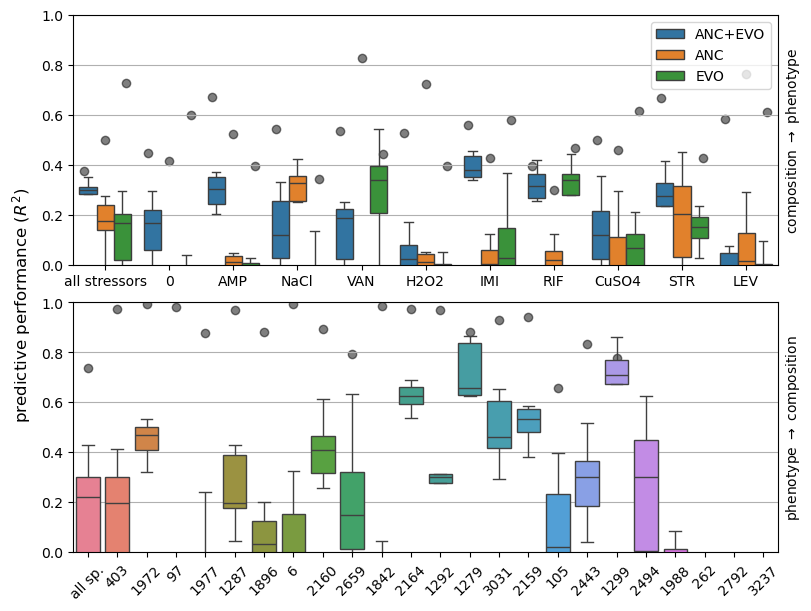

In [27]:
fig = plt.figure(figsize=(8, 6), constrained_layout=True)
fig.supylabel(r"predictive performance ($R^2$)",)
gs = fig.add_gridspec(2, 1)

# top: composition to phenotype

ax = fig.add_subplot(gs[0,0])

ax.scatter(np.arange(0, len(F2R_all["trn_avg"]) ) / 3 - 1/3, F2R_all["trn_avg"], c="k", alpha = 0.5)

sns.boxplot(data = F2R_all.drop(["trn_avg", "trn_mdn"], axis = 1).T.melt(),
            ax = ax, showfliers=False, x = "strs", y = "value", hue = "hist")
ax.set(ylim = (0,1), xlabel = "", ylabel = r"composition $\to$ phenotype")
ax.grid(visible=True, axis = "y")
ax.yaxis.set_label_position("right")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels)

# bottom: phenotype to composition

ax = fig.add_subplot(gs[1,:], )

ax.scatter(range(len(R2F["trn_avg"])), R2F["trn_avg"], c="k", alpha = 0.5 )
sns.boxplot(data = R2F.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False)
ax.set(xlim = (-0.5,23.5), ylim = (0,1), xlabel = "", ylabel = r"phenotype $\to$ composition",)
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")#xdata = np.arange(8) * 3)
ax.yaxis.set_label_position("right")

### SAVING
name = "{}/plot/AE.pdf".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## From frequencies to phenotypes [not used]

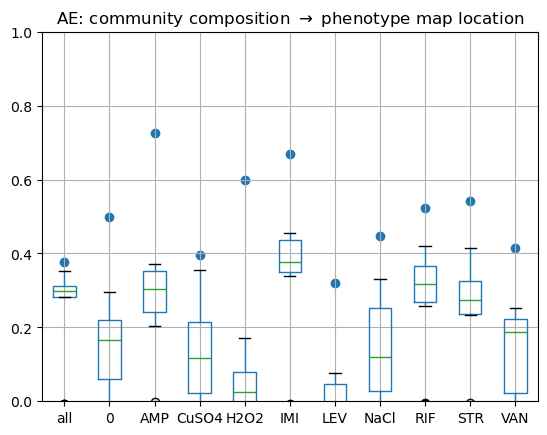

In [8]:
F2R = pd.read_csv("{}/data/autoencoder_F2R.csv".format(cwd), index_col=[0])

ax = F2R.drop(["trn_avg", "trn_mdn"], axis = 1).T.boxplot(return_type="axes")
ax.scatter(range(1, len(F2R["trn_avg"]) + 1), F2R["trn_avg"], )
ax.set(ylim = (0,1), title = r"AE: community composition $\to$ phenotype map location")

### SAVING
name = "{}/plot/AE_F2R.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## From phenotypes to frequencies [not used]

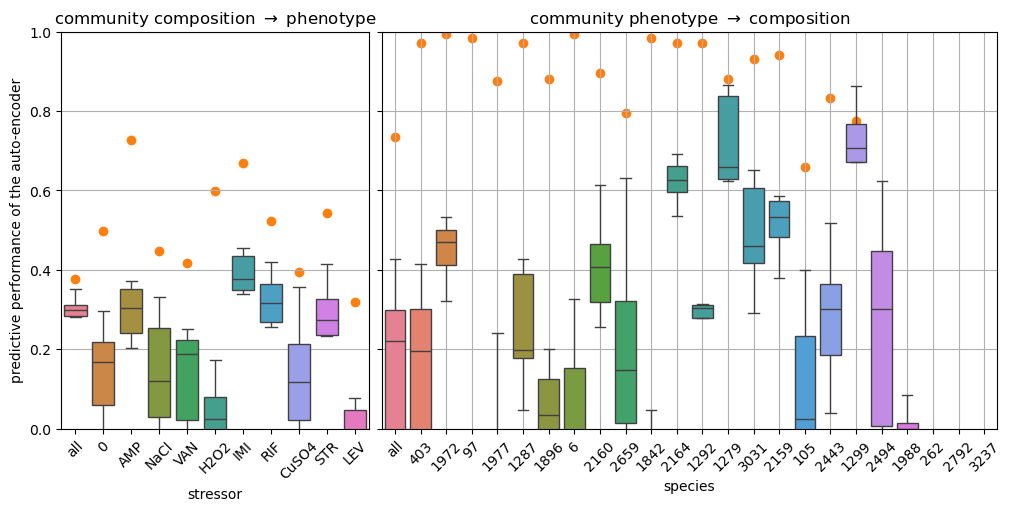

In [15]:
F2R = pd.read_csv("{}/data/autoencoder_F2R.csv".format(cwd), index_col=[0]).loc[R_index]
R2F = pd.read_csv("{}/data/autoencoder_R2F.csv".format(cwd), index_col=[0]).loc[F_index]

fig = plt.figure(figsize=(10, 5), constrained_layout=True)
gs = fig.add_gridspec(1, 3)

ax = fig.add_subplot(gs[:,0])

sns.boxplot(data = F2R.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False, )
ax.scatter(range(len(F2R["trn_avg"])), F2R["trn_avg"], )
ax.set(xlim = (-0.5,10.5), ylim = (0,1),
       xlabel = "stressor", ylabel = "predictive performance of the auto-encoder",
       title = r"community composition $\to$ phenotype", )
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

ax = fig.add_subplot(gs[:,1:], )

sns.boxplot(data = R2F.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False)
ax.scatter(range(len(R2F["trn_avg"])), R2F["trn_avg"], )
ax.set(xlim = (-0.5,23.5), ylim = (0,1), yticklabels = [],
       xlabel = "species",
       title = r"community phenotype $\to$ composition",)
ax.tick_params("x", rotation=45)
ax.grid(visible=True, xdata = np.arange(8) * 3)

### SAVING
name = "{}/plot/AE.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

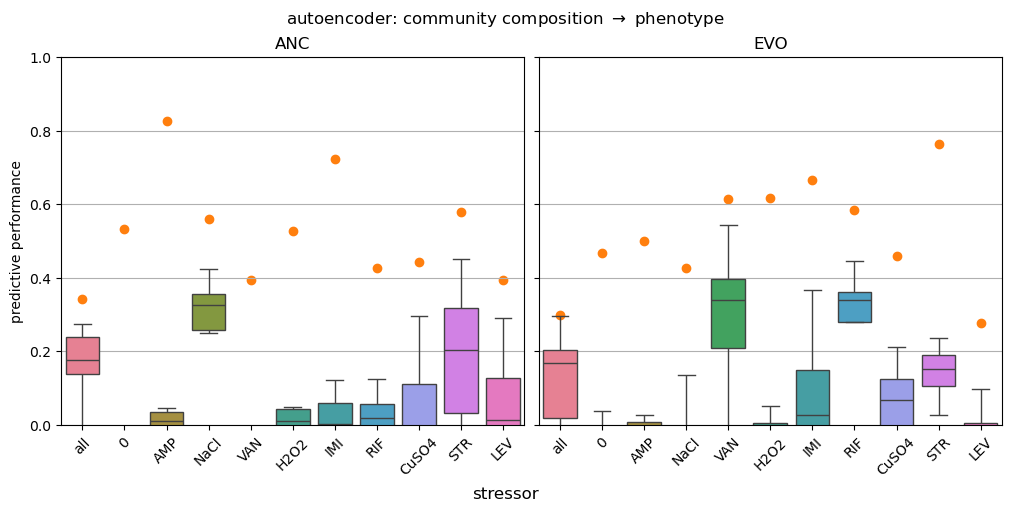

In [16]:
F2R_ANC = pd.read_csv("{}/data/autoencoder_F2R_ANC.csv".format(cwd), index_col=[0]).loc[R_index]
F2R_EVO = pd.read_csv("{}/data/autoencoder_F2R_EVO.csv".format(cwd), index_col=[0]).loc[R_index]

fig = plt.figure(figsize=(10, 5), constrained_layout=True)
fig.suptitle(r"autoencoder: community composition $\to$ phenotype",)
fig.supxlabel("stressor",)
gs = fig.add_gridspec(1, 2)

ax = fig.add_subplot(gs[:,0])

ax = sns.boxplot(data = F2R_ANC.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False, )
ax.scatter(range(len(F2R_ANC["trn_avg"])), F2R_ANC["trn_avg"], )
ax.set(xlim = (-0.5,10.5), ylim = (0,1), ylabel = "predictive performance",
       title = "ANC" )
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

ax = fig.add_subplot(gs[:,1], )

ax = sns.boxplot(data = F2R_EVO.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False, )
ax.scatter(range(len(F2R_EVO["trn_avg"])), F2R_EVO["trn_avg"], )
ax.set(xlim = (-0.5,10.5), ylim = (0,1), yticklabels = [],
       title = "EVO", )
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

### SAVING
name = "{}/plot/AE_F2R_ANC_EVO.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

In [26]:
F2R = pd.read_csv("{}/data/autoencoder_F2R.csv".format(cwd), index_col=[0])
F2R_ANC = pd.read_csv("{}/data/autoencoder_F2R_ANC.csv".format(cwd), index_col=[0])#.loc[F_index]
F2R_EVO = pd.read_csv("{}/data/autoencoder_F2R_EVO.csv".format(cwd), index_col=[0])#.loc[F_index]

F2R_all = pd.concat({"ANC&EVO": F2R, "ANC": F2R_ANC, "EVO": F2R_EVO, }, names = ["hist", "strs"])

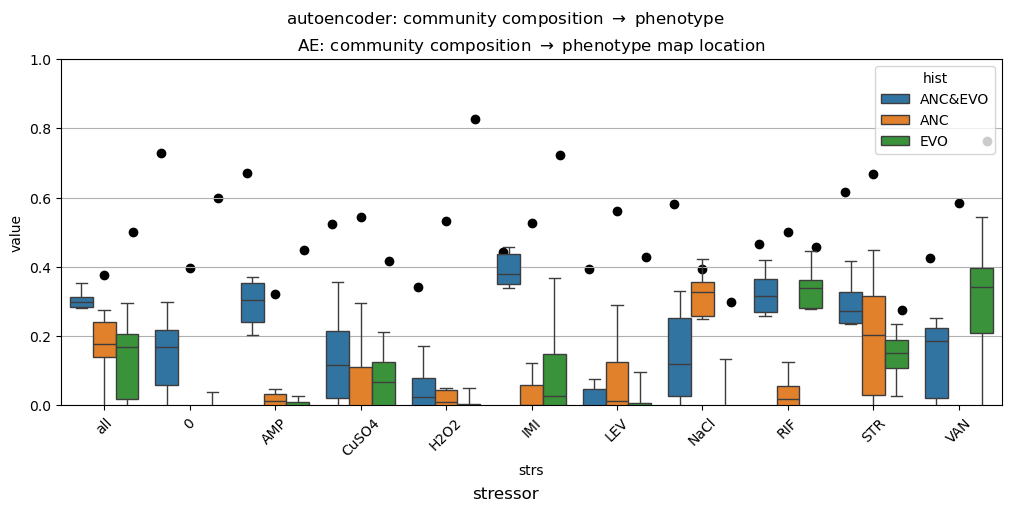

In [28]:
fig = plt.figure(figsize=(10, 5), constrained_layout=True)
fig.suptitle(r"autoencoder: community composition $\to$ phenotype",)
fig.supxlabel("stressor",)
ax = fig.add_subplot()

ax.scatter(np.arange(0, len(F2R_all["trn_avg"]) ) / 3 , F2R_all["trn_avg"], c="k")

sns.boxplot(data = F2R_all.drop(["trn_avg", "trn_mdn"], axis = 1).T.melt(),
            ax = ax, showfliers=False, x = "strs", y = "value", hue = "hist")
ax.set(ylim = (0,1), title = r"AE: community composition $\to$ phenotype map location")
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

### SAVING
name = "{}/plot/AE_F2R_all.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()